# TP LangGraph — Gestion et accompagnement des étudiants (Groq API)

**Objectif :** reprendre les deux mécanismes du TP original en changeant le domaine d'application :

1. construire un workflow conditionnel qui analyse un dossier étudiant et choisit un parcours de suivi ;
2. construire un agent conversationnel qui peut appeler des outils Python pour calculer des indicateurs académiques.

Le TP conserve les notions centrales de LangGraph : `StateGraph`, état partagé, nœuds, arêtes, routage conditionnel, `ToolNode`, LLM et boucle d'appel d'outils.

> Les exemples de notes et de présences sont fictifs. La règle de décision du premier workflow est uniquement pédagogique : elle peut être adaptée au règlement réel d'un établissement.


In [1]:
import os
from dotenv import load_dotenv

from typing import Annotated, Literal, TypedDict

from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

load_dotenv()
print("Imports terminés.")


Imports terminés.


# Partie 1 — Workflow conditionnel pour le suivi des étudiants

## 1. Définir l'état partagé

L'état représente le dossier de l'étudiant. Il contient son nom, sa moyenne, le nombre d'absences, la décision prise par le workflow et le résultat du traitement.

La décision peut prendre deux valeurs :
- `standard_followup` : suivi pédagogique standard ;
- `academic_support` : accompagnement pédagogique renforcé.


In [2]:
class StudentState(TypedDict):
    name: str
    average: float
    absences: int
    decision: Literal["standard_followup", "academic_support"]
    result: str


## 2. Créer le nœud d'analyse

Ce nœud lit les informations de l'étudiant et choisit une orientation. Dans cet exemple, le suivi est standard si la moyenne est au moins égale à 10/20 et si le nombre d'absences ne dépasse pas 5. Dans les autres cas, l'étudiant est orienté vers un accompagnement renforcé.


In [3]:
def analyze_student(state: StudentState) -> StudentState:
    average = state["average"]
    absences = state["absences"]

    if average >= 10 and absences <= 5:
        state["decision"] = "standard_followup"
    else:
        state["decision"] = "academic_support"

    print(f"Le dossier de {state['name']} a été analysé.")
    return state


## 3. Créer les deux nœuds de traitement

Chaque nœud représente une action différente selon la décision prise par le nœud d'analyse.


In [4]:
def standard_followup_process(state: StudentState) -> StudentState:
    state["result"] = (
        f"Le dossier de {state['name']} est orienté vers un suivi pédagogique standard."
    )
    print("*" * 80)
    print(state["result"])
    print("*" * 80)
    return state


In [5]:
def academic_support_process(state: StudentState) -> StudentState:
    state["result"] = (
        f"Le dossier de {state['name']} est orienté vers un accompagnement pédagogique renforcé."
    )
    print("=" * 80)
    print(state["result"])
    print("=" * 80)
    return state


## 4. Définir la fonction de routage

La fonction de routage lit la valeur `decision` produite par le nœud d'analyse. LangGraph utilisera cette valeur pour choisir le prochain nœud.


In [6]:
def student_router(state: StudentState) -> Literal["standard_followup", "academic_support"]:
    return state["decision"]


## 5. Construire et compiler le graphe

Le workflow commence par `analyze_node`. Le routage conditionnel sélectionne ensuite l'un des deux nœuds de traitement. Les deux chemins se terminent par `END`.


In [7]:
workflow = StateGraph(StudentState)

workflow.add_node("analyze_node", analyze_student)
workflow.add_node("standard_followup_node", standard_followup_process)
workflow.add_node("academic_support_node", academic_support_process)

workflow.add_edge(START, "analyze_node")

workflow.add_conditional_edges(
    "analyze_node",
    student_router,
    {
        "standard_followup": "standard_followup_node",
        "academic_support": "academic_support_node",
    },
)

workflow.add_edge("standard_followup_node", END)
workflow.add_edge("academic_support_node", END)

graph = workflow.compile()
print("Workflow compilé avec succès.")


Workflow compilé avec succès.


### Visualiser le graphe

Le diagramme permet de voir le nœud d'analyse, les deux branches possibles et leur fin. Si le rendu PNG échoue dans l'environnement local, la représentation Mermaid reste disponible avec `graph.get_graph().draw_mermaid()`.


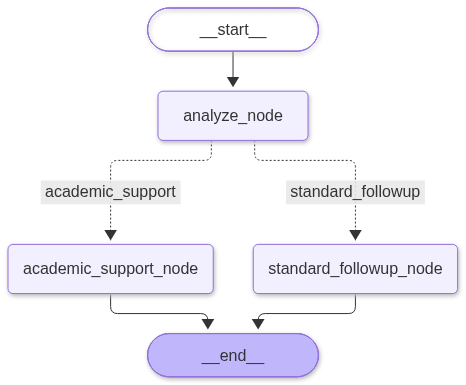

In [8]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as error:
    print("Le rendu PNG n'est pas disponible dans cet environnement.")
    print("Diagramme Mermaid :")
    print(graph.get_graph().draw_mermaid())
    print(f"Détail technique : {error}")


## 6. Tester le workflow

### Cas 1 : étudiant avec un suivi standard

La moyenne de Lina est supérieure ou égale à 10 et elle a au plus 5 absences. Le workflow doit choisir le suivi standard.


In [9]:
result_standard = graph.invoke({
    "name": "Lina",
    "average": 14.5,
    "absences": 2,
})

print("\nRésultat final :", result_standard["result"])


Le dossier de Lina a été analysé.
********************************************************************************
Le dossier de Lina est orienté vers un suivi pédagogique standard.
********************************************************************************

Résultat final : Le dossier de Lina est orienté vers un suivi pédagogique standard.


### Cas 2 : étudiant nécessitant un accompagnement renforcé

Yassine a une moyenne inférieure à 10 et plusieurs absences. Le workflow doit sélectionner l'accompagnement renforcé.


In [10]:
result_support = graph.invoke({
    "name": "Yassine",
    "average": 8.5,
    "absences": 7,
})

print("\nRésultat final :", result_support["result"])


Le dossier de Yassine a été analysé.
Le dossier de Yassine est orienté vers un accompagnement pédagogique renforcé.

Résultat final : Le dossier de Yassine est orienté vers un accompagnement pédagogique renforcé.


# Partie 2 — Création d'un agent étudiant avec des outils

Dans cette partie, on construit un agent qui reçoit une question en langage naturel. Le modèle de langage peut décider d'appeler des fonctions Python spécialisées :

- calculer la moyenne d'une liste de notes ;
- calculer le taux de présence ;
- vérifier si une moyenne atteint le seuil de validation.

Le fonctionnement général est le suivant : `assistant` appelle le LLM ; si le LLM demande un outil, le graphe passe à `tools` ; après l'exécution de l'outil, le résultat revient à `assistant`. La boucle s'arrête lorsque le LLM fournit une réponse finale sans nouvel appel d'outil.


## 7. Importer les composants nécessaires

`@tool` transforme une fonction Python en outil utilisable par le modèle. `ToolNode` exécute les outils demandés. `add_messages` conserve l'historique des messages dans l'état du graphe.


In [11]:
from langchain_core.tools import tool
from langchain_core.messages import AnyMessage, HumanMessage, SystemMessage
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_groq import ChatGroq

## 8. Définir les outils de l'agent

Chaque fonction est décorée par `@tool`. Sa docstring explique au modèle quand et comment l'utiliser. Les contrôles évitent les entrées incohérentes.


In [12]:
@tool
def calculate_average(grades: list[float]) -> float:
    """Calculate the arithmetic average of a student's grades out of 20."""
    if not grades:
        raise ValueError("La liste des notes ne peut pas être vide.")
    if any(grade < 0 or grade > 20 for grade in grades):
        raise ValueError("Chaque note doit être comprise entre 0 et 20.")

    average = sum(grades) / len(grades)
    print(f"Calcul de la moyenne à partir de {len(grades)} notes : {average:.2f}/20")
    return round(average, 2)


@tool
def calculate_attendance_rate(present_sessions: int, total_sessions: int) -> float:
    """Calculate the student's attendance rate as a percentage."""
    if total_sessions <= 0:
        raise ValueError("Le nombre total de séances doit être supérieur à zéro.")
    if present_sessions < 0 or present_sessions > total_sessions:
        raise ValueError("Le nombre de présences doit être entre 0 et le total des séances.")

    rate = (present_sessions / total_sessions) * 100
    print(f"Calcul du taux de présence : {rate:.2f}%")
    return round(rate, 2)


@tool
def check_validation(average: float, threshold: float = 10.0) -> str:
    """Check whether a student's average reaches the required validation threshold."""
    if not 0 <= average <= 20:
        raise ValueError("La moyenne doit être comprise entre 0 et 20.")
    if not 0 <= threshold <= 20:
        raise ValueError("Le seuil doit être compris entre 0 et 20.")

    status = "validé" if average >= threshold else "non validé"
    print(f"Vérification de la validation : {status}")
    return status


### Regrouper les outils

Cette liste sera transmise au modèle puis au nœud `ToolNode`.


In [13]:
tools = [calculate_average, calculate_attendance_rate, check_validation]
print("Outils disponibles :", [tool.name for tool in tools])


Outils disponibles : ['calculate_average', 'calculate_attendance_rate', 'check_validation']


## 9. Définir l'état de l'agent

L'état contient la liste des messages. L'annotateur `add_messages` permet d'ajouter les nouveaux messages à l'historique plutôt que de remplacer toute la conversation.


In [14]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]


## 10. Initialiser le modèle de langage Groq et lui associer les outils

On utilise `ChatGroq` avec le modèle `llama-3.3-70b-versatile`, qui prend en charge l'appel d'outils. Il faut disposer d'une clé API Groq valide dans le fichier `.env`.

In [20]:
if not os.getenv("GROQ_API_KEY"):
    raise RuntimeError(
        "GROQ_API_KEY est introuvable. Ajoutez-la dans le fichier .env puis relancez cette cellule."
    )

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)
llm_with_tools = llm.bind_tools(tools)
print("Modèle Groq initialisé et outils associés.")

Modèle Groq initialisé et outils associés.


## 11. Créer le nœud assistant et la fonction de décision

Le nœud `assistant` envoie les messages au LLM et ajoute sa réponse à l'état. La fonction `should_continue` vérifie ensuite si le dernier message contient des appels d'outils.


In [21]:
def assistant(state: AgentState) -> dict:
    response = llm_with_tools.invoke(state["messages"])
    print("LLM invoqué.")
    return {"messages": [response]}


def should_continue(state: AgentState) -> Literal["continue", "end"]:
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "continue"
    return "end"


## 12. Construire le graphe de l'agent

Le parcours correct est :

`START → assistant → (tools → assistant)* → END`

La branche `continue` va vers `tools`, et non vers `assistant`, afin que les fonctions demandées par le modèle soient réellement exécutées.


In [22]:
agent_workflow = StateGraph(AgentState)

agent_workflow.add_node("assistant", assistant)
agent_workflow.add_node("tools", ToolNode(tools=tools))

agent_workflow.add_edge(START, "assistant")

agent_workflow.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "continue": "tools",
        "end": END,
    },
)

agent_workflow.add_edge("tools", "assistant")

agent = agent_workflow.compile()
print("Agent compilé avec succès.")


Agent compilé avec succès.


### Visualiser le graphe de l'agent


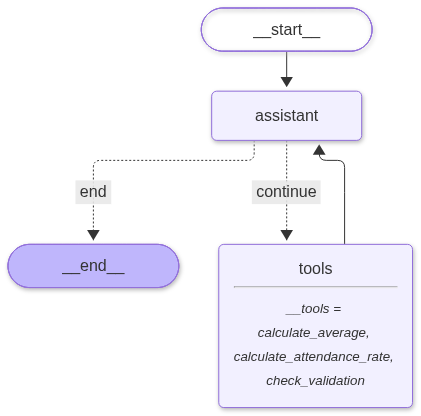

In [23]:
try:
    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception as error:
    print(agent.get_graph().draw_mermaid())
    print(f"Rendu PNG non disponible : {error}")


## 13. Tester l'agent

On demande à l'agent d'analyser les notes et les présences d'une étudiante. Le message lui demande explicitement d'utiliser les outils nécessaires.


In [24]:
system_message = SystemMessage(
    content=(
        "Tu es un assistant pédagogique. Réponds en français, de manière claire. "
        "Pour les calculs de notes, de présence ou de validation, utilise les outils disponibles "
        "au lieu de faire les calculs mentalement. Explique ensuite les résultats."
    )
)

user_message = HumanMessage(
    content=(
        "Je suis Sara. Mes notes sont 12, 15, 9 et 14 sur 20. "
        "J'ai assisté à 18 séances sur 20. "
        "Calcule ma moyenne, mon taux de présence et vérifie si je valide avec un seuil de 10/20."
    )
)

agent_result = agent.invoke({"messages": [system_message, user_message]})


LLM invoqué.
Calcul de la moyenne à partir de 4 notes : 12.50/20
LLM invoqué.
Calcul du taux de présence : 90.00%
LLM invoqué.
Vérification de la validation : validé
LLM invoqué.


### Afficher l'historique des messages

On affiche les messages de l'agent, y compris les éventuelles demandes d'outils et les réponses des outils, puis la réponse finale.


In [25]:
for message in agent_result["messages"]:
    print("\n" + "-" * 80)
    print("Type :", message.type)

    if message.type == "ai" and getattr(message, "tool_calls", None):
        print("Appels d'outils :", message.tool_calls)

    if message.content:
        print("Contenu :", message.content)



--------------------------------------------------------------------------------
Type : system
Contenu : Tu es un assistant pédagogique. Réponds en français, de manière claire. Pour les calculs de notes, de présence ou de validation, utilise les outils disponibles au lieu de faire les calculs mentalement. Explique ensuite les résultats.

--------------------------------------------------------------------------------
Type : human
Contenu : Je suis Sara. Mes notes sont 12, 15, 9 et 14 sur 20. J'ai assisté à 18 séances sur 20. Calcule ma moyenne, mon taux de présence et vérifie si je valide avec un seuil de 10/20.

--------------------------------------------------------------------------------
Type : ai
Appels d'outils : [{'name': 'calculate_average', 'args': {'grades': [12, 15, 9, 14]}, 'id': 'fc_bfb04eec-ff34-4c43-b509-74d1bfd480f4', 'type': 'tool_call'}]

--------------------------------------------------------------------------------
Type : tool
Contenu : 12.5

--------------------